In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler
import torch
from torch.utils.data import TensorDataset, DataLoader

In [3]:

df = pd.read_csv("Dimuon_Singlemu.csv")
df

,Run,Event,type1,Q1,pt1,eta1,phi1,E1,px1,py1,...,type2,Q2,pt2,eta2,phi2,E2,px2,py2,pz2,M
0,166699,835716681,G,1,4.2116,2.2366,-0.4849,19.9382,3.7261,-1.9631,...,T,-1,1.2556,2.2683,-1.4488,6.1319,0.1528,-1.2463,6.0011,2.1330
1,166699,836133459,G,-1,2.1479,-2.0159,-2.7753,8.2066,-2.0055,-0.7692,...,G,1,19.5453,-1.0826,-0.3408,32.1613,18.4210,-6.5332,-25.5406,13.6786
2,166699,836165498,G,1,21.0732,1.5948,-1.1137,54.0560,9.2997,-18.9102,...,T,-1,2.3864,1.5352,-1.7388,5.7968,-0.3991,-2.3528,5.2818,4.3813
3,166699,836249706,G,1,18.5889,1.6422,1.1923,49.8180,6.8688,17.2734,...,G,-1,1.8721,1.9704,1.6393,6.8459,-0.1281,1.8678,6.5841,3.2587
4,166699,835608783,G,-1,11.8194,0.8711,-1.5811,16.5947,-0.1214,-11.8187,...,T,1,0.9408,2.0107,-1.6559,3.5779,-0.0799,-0.9374,3.4504,4.0171
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83756,171880,168748742,G,-1,1.8023,2.3706,-0.9321,9.7302,1.0744,-1.4470,...,T,1,1.7895,1.4432,0.4109,4.0011,1.6405,0.7147,3.5770,2.8234
83757,171880,168741216,G,1,36.9262,2.2307,2.8742,173.8090,-35.6137,9.7576,...,T,-1,6.1773,2.2084,2.7668,28.4510,-5.7485,2.2615,27.7721,1.6556
83758,171880,169006248,G,1,17.1378,-0.2433,0.2400,17.8220,16.8113,4.1122,...,T,-1,1.0959,1.7140,-0.3812,3.1424,1.0173,-0.4077,2.9432,10.2510
83759,171880,168784352,G,1,4.5931,-1.1897,1.5863,8.2465,-0.0712,4.5926,...,G,-1,23.9671,-1.2769,1.6562,46.3079,-2.0451,23.8797,-39.6231,1.1724


In [4]:

df = df.drop(columns=['Run', 'Event'])
df

,type1,Q1,pt1,eta1,phi1,E1,px1,py1,pz1,type2,Q2,pt2,eta2,phi2,E2,px2,py2,pz2,M
0,G,1,4.2116,2.2366,-0.4849,19.9382,3.7261,-1.9631,19.4881,T,-1,1.2556,2.2683,-1.4488,6.1319,0.1528,-1.2463,6.0011,2.1330
1,G,-1,2.1479,-2.0159,-2.7753,8.2066,-2.0055,-0.7692,-7.9199,G,1,19.5453,-1.0826,-0.3408,32.1613,18.4210,-6.5332,-25.5406,13.6786
2,G,1,21.0732,1.5948,-1.1137,54.0560,9.2997,-18.9102,49.7791,T,-1,2.3864,1.5352,-1.7388,5.7968,-0.3991,-2.3528,5.2818,4.3813
3,G,1,18.5889,1.6422,1.1923,49.8180,6.8688,17.2734,46.2199,G,-1,1.8721,1.9704,1.6393,6.8459,-0.1281,1.8678,6.5841,3.2587
4,G,-1,11.8194,0.8711,-1.5811,16.5947,-0.1214,-11.8187,11.6479,T,1,0.9408,2.0107,-1.6559,3.5779,-0.0799,-0.9374,3.4504,4.0171
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83756,G,-1,1.8023,2.3706,-0.9321,9.7302,1.0744,-1.4470,9.5612,T,1,1.7895,1.4432,0.4109,4.0011,1.6405,0.7147,3.5770,2.8234
83757,G,1,36.9262,2.2307,2.8742,173.8090,-35.6137,9.7576,169.8410,T,-1,6.1773,2.2084,2.7668,28.4510,-5.7485,2.2615,27.7721,1.6556
83758,G,1,17.1378,-0.2433,0.2400,17.8220,16.8113,4.1122,-4.2526,T,-1,1.0959,1.7140,-0.3812,3.1424,1.0173,-0.4077,2.9432,10.2510
83759,G,1,4.5931,-1.1897,1.5863,8.2465,-0.0712,4.5926,-6.8481,G,-1,23.9671,-1.2769,1.6562,46.3079,-2.0451,23.8797,-39.6231,1.1724


In [5]:
df['eta_diff'] = df['eta1'] - df['eta2']

# The Pseudorapidity Difference between eta1 (pseudorapidity of 1st particle) and eta2 (pseudorapidity of 2nd particle) values

In [6]:
df['phi_diff'] = np.arctan2(np.sin(df['phi1'] - df['phi2']), np.cos(df['phi1'] - df['phi2']))

# The Formula for Azimuthal Angle

In [7]:
df['delta_R'] = np.sqrt(df['eta_diff']**2 + df['phi_diff']**2)

# The Formula for the Angular Seperation between the muons

In [8]:

df['pt_ratio'] = df['pt1'] / (df['pt2'] + 1e-5)

# The Ratio between the Transverse Momentum of 1st Particle and the 2nd particle

In [9]:
df['pt_sum'] = df['pt1'] + df['pt2']

# The Sum of the Transverse Momentum of 1st Particle and the 2nd particle

In [10]:
df['E_total'] = df['E1'] + df['E2']

# The Sum of Total Relativistic Energy of each particle

In [11]:
df['px_total'] = df['px1'] + df['px2']

# The Sum of the Horizontal momentum component or Momentum along X axis of both particle

In [12]:
df['py_total'] = df['py1'] + df['py2']

# The Sum of the Vertical Momentum component or Momentum along Y axis of both particle

In [13]:
df['pz_total'] = df['pz1'] + df['pz2']

# The Sum of the Longitudinal Momentum (Momentum along beam direction) of both particle

In [14]:

df['calculated_M'] = np.sqrt(np.clip(df['E_total']**2 - (df['px_total']**2 + df['py_total']**2 + df['pz_total']**2), 0, None))

# Calculates the Dimuon Invariant Mass using the 4 vectors of the 2 muons

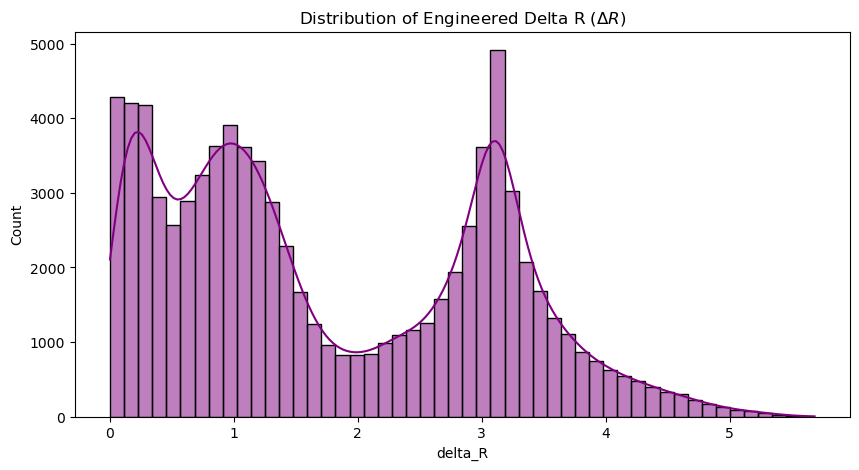

In [15]:
plt.figure(figsize=(10, 5))
sns.histplot(df['delta_R'], kde=True, bins=50, color='purple')
plt.title("Distribution of Engineered Delta R ($\Delta R$)")
plt.show()


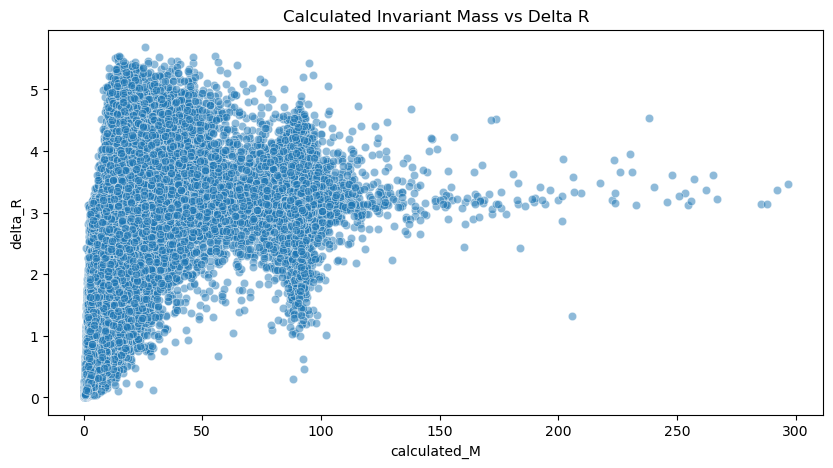

In [16]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x='calculated_M', y='delta_R', alpha=0.5)
plt.title("Calculated Invariant Mass vs Delta R")
plt.show()

In [17]:
df['type1'] = df['type1'].map({'G': 1, 'T': 0}).fillna(-1)

# Here G represents Global Muons and T represents Tracker Muons

df['type2'] = df['type2'].map({'G': 1, 'T': 0}).fillna(-1)


In [18]:
df['type1'].value_counts()

type1
1    83761
Name: count, dtype: int64

In [19]:
df['type2'].value_counts()

type2
0    49019
1    34742
Name: count, dtype: int64

In [20]:
df = df.drop_duplicates()

In [21]:
df = df.fillna(df.median())


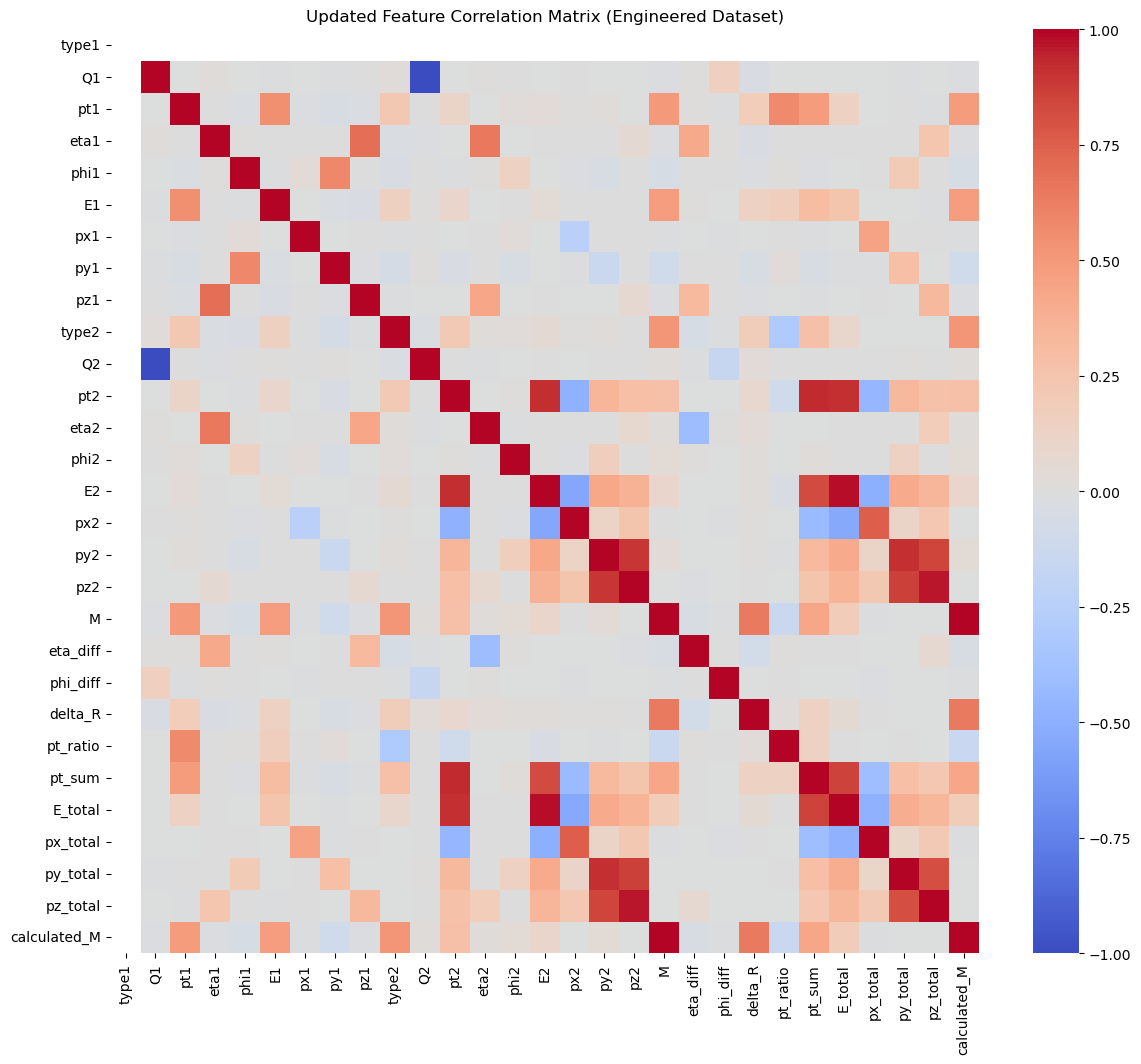

In [22]:
plt.figure(figsize=(14, 12))
sns.heatmap(df.corr(), annot=False, cmap="coolwarm", center=0)
plt.title("Updated Feature Correlation Matrix (Engineered Dataset)")
plt.show()

In [23]:
X = df.drop(columns=['M', 'calculated_M'])
y = df['M']

In [24]:
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.15, random_state=42)

# Splits the data into 2 parts
# X_test and y_test are used to evaluate the model in the final (15% = 12,564.15 events)
# X_train_val and y_train_val are used as datasets for another split (85% = 71,196.85 events)

X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.1765, random_state=42)

# Splits X_train_val and y_train_val into 2 parts

# X_val and y_val are used to evaluate this seperate model (17.65% = 4,033.815 events)
# X_train and y_train are used to train the model (82.35% = 67,163.034 events)

<h1> RobustScaler

This method is **robust to outliers**.  
Instead of using the mean (which outliers skew), it uses the **median** and the **interquartile range (IQR)** (the middle 50% of data).

*   **`fit_transform(X_train)`**: We calculate the median and IQR **only** from the training data. This is crucial to prevent *data leakage*.
*   **`transform(...)`**: We apply those *exact same* numbers to the validation and test sets. This keeps everything consistent.


In [25]:
scaler_X = RobustScaler()
X_train_scaled = scaler_X.fit_transform(X_train)
X_val_scaled = scaler_X.transform(X_val)
X_test_scaled = scaler_X.transform(X_test)


<h1> StandardScaler

This method assumes data is **normal (Gaussian)**. It removes the mean and scales to **unit variance**. It helps regression models learn faster.

*   `.reshape(-1, 1)`: The scaler needs a **2D column**, but `y` is usually a flat list. This turns it into a column.
*   `.flatten()`: After scaling, we turn it back into a **flat list** (1D) because that's what models expect for targets.


In [26]:
scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1, 1)).flatten()
y_val_scaled = scaler_y.transform(y_val.values.reshape(-1, 1)).flatten()
y_test_scaled = scaler_y.transform(y_test.values.reshape(-1, 1)).flatten()

*    `.Outliers in features (X) do not distort the scaling (via RobustScaler).
*    `.Target values (y) are normalized to a standard range (via StandardScaler).
*    `.No data leakage occurs because .fit() is called only on the training set, while .transform() is used for validation and test sets.

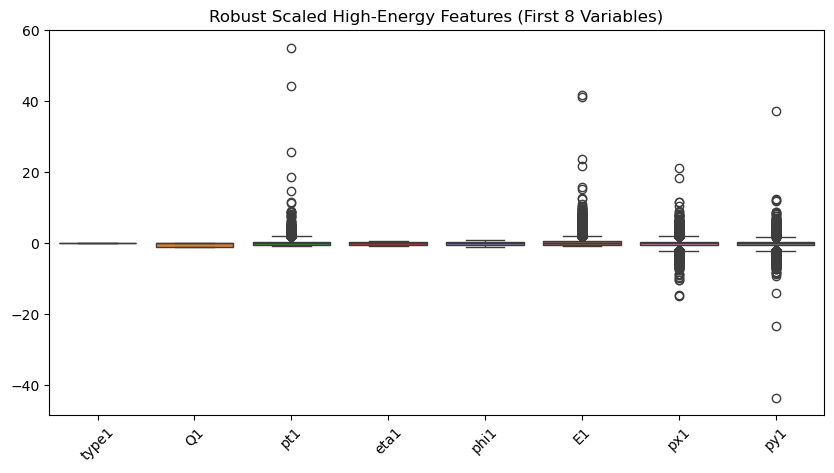

In [27]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=pd.DataFrame(X_train_scaled, columns=X.columns).iloc[:, :8])
plt.title("Robust Scaled High-Energy Features (First 8 Variables)")
plt.xticks(rotation=45)
plt.show()

In [28]:
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_scaled, dtype=torch.float32).unsqueeze(1)

In [29]:
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_scaled, dtype=torch.float32).unsqueeze(1)

In [30]:
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_scaled, dtype=torch.float32).unsqueeze(1)

In [31]:
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

In [32]:
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=512, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=512, shuffle=False)

In [33]:
print(f"Standard PyTorch Tensor Shapes (Dense / Autoencoder): {X_train_tensor.shape}, {y_train_tensor.shape}")

print(f"Input Tensor Shape: {X_train_tensor.shape}")
print(f"Target Tensor Shape: {y_train_tensor.shape}")
print(f"Batch Example Shape: {next(iter(train_loader))[0].shape}")

Standard PyTorch Tensor Shapes (Dense / Autoencoder): torch.Size([58629, 27]), torch.Size([58629, 1])
Input Tensor Shape: torch.Size([58629, 27])
Target Tensor Shape: torch.Size([58629, 1])
Batch Example Shape: torch.Size([256, 27])


<h1>Training the Model

In [34]:
import torch.nn as nn
import torch.optim as optim

In [35]:
class StabilizedMassRegressor(nn.Module):
    def __init__(self, input_dim):
        super(StabilizedMassRegressor, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.LayerNorm(128),  # Swapped BatchNorm for LayerNorm to stabilize validation
            nn.SiLU(),          # SiLU (Swish) often works smoother than ReLU for physics regressions
            nn.Dropout(0.1),    # Reduced dropout to prevent erratic step-updates
            
            nn.Linear(128, 64),
            nn.LayerNorm(64),
            nn.SiLU(),
            nn.Dropout(0.1),
            
            nn.Linear(64, 32),
            nn.SiLU(),
            
            nn.Linear(32, 1)
        )
        
    def forward(self, x):
        return self.network(x)

In [36]:
input_features_dim = X_train_tensor.shape[1]
model = StabilizedMassRegressor(input_dim=input_features_dim)

In [37]:
criterion = nn.MSELoss()

# Lowered learning rate for smoother optimization steps

optimizer = optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-3)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=4)

In [38]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)

In [39]:
epochs = 20
train_losses = []
val_losses = []

In [40]:
for epoch in range(epochs):
    model.train()
    running_train_loss = 0.0
    
    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        
        optimizer.zero_grad()
        predictions = model(batch_X)
        loss = criterion(predictions, batch_y)
        loss.backward()
        optimizer.step()
        
        running_train_loss += loss.item() * batch_X.size(0)
        
    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    train_losses.append(epoch_train_loss)
    
    model.eval()
    running_val_loss = 0.0
    
    with torch.no_grad():
        for batch_X, batch_y in val_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            predictions = model(batch_X)
            loss = criterion(predictions, batch_y)
            running_val_loss += loss.item() * batch_X.size(0)
            
    epoch_val_loss = running_val_loss / len(val_loader.dataset)
    val_losses.append(epoch_val_loss)
    
    scheduler.step(epoch_val_loss)

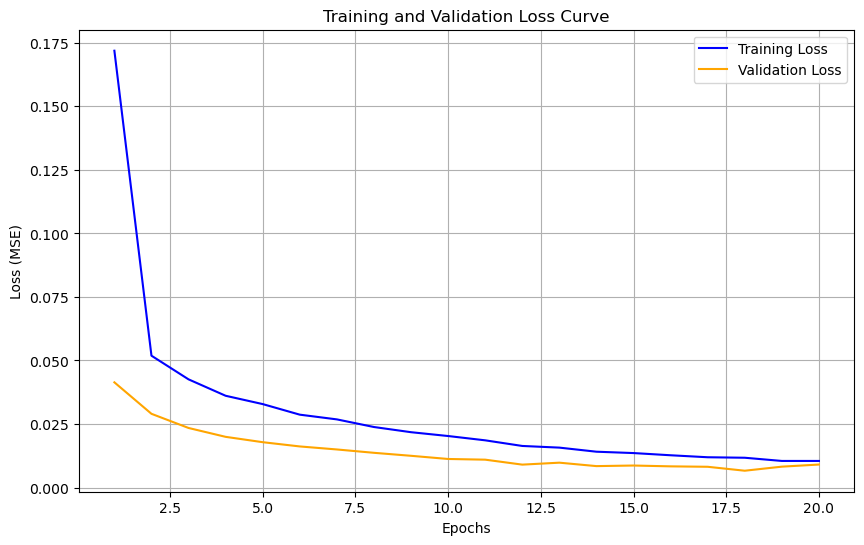

In [41]:
plt.figure(figsize=(10, 6))
plt.plot(range(1, epochs + 1), train_losses, label='Training Loss', color='blue')
plt.plot(range(1, epochs + 1), val_losses, label='Validation Loss', color='orange')
plt.xlabel('Epochs')
plt.ylabel('Loss (MSE)')
plt.title('Training and Validation Loss Curve')
plt.legend()
plt.grid(True)
plt.show()

<h1> Evaluation

In [42]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [43]:
model.eval()
test_predictions = []
test_targets = []

In [44]:
with torch.no_grad():
    for batch_X, batch_y in test_loader:
        batch_X = batch_X.to(device)
        predictions = model(batch_X)
        test_predictions.append(predictions.cpu().numpy())
        test_targets.append(batch_y.numpy())

In [45]:
test_predictions = np.vstack(test_predictions)
test_targets = np.vstack(test_targets)

In [46]:
y_pred_original = scaler_y.inverse_transform(test_predictions).flatten()
y_true_original = scaler_y.inverse_transform(test_targets).flatten()

In [47]:
r2 = r2_score(y_true_original, y_pred_original)
mae = mean_absolute_error(y_true_original, y_pred_original)
mse = mean_squared_error(y_true_original, y_pred_original)
rmse = np.sqrt(mse)

In [48]:
print(f"Test R2 Score: {r2:.4f}")
print(f"Test MAE: {mae:.4f} GeV")
print(f"Test RMSE: {rmse:.4f} GeV")

Test R2 Score: 0.9947
Test MAE: 1.1778 GeV
Test RMSE: 2.2749 GeV


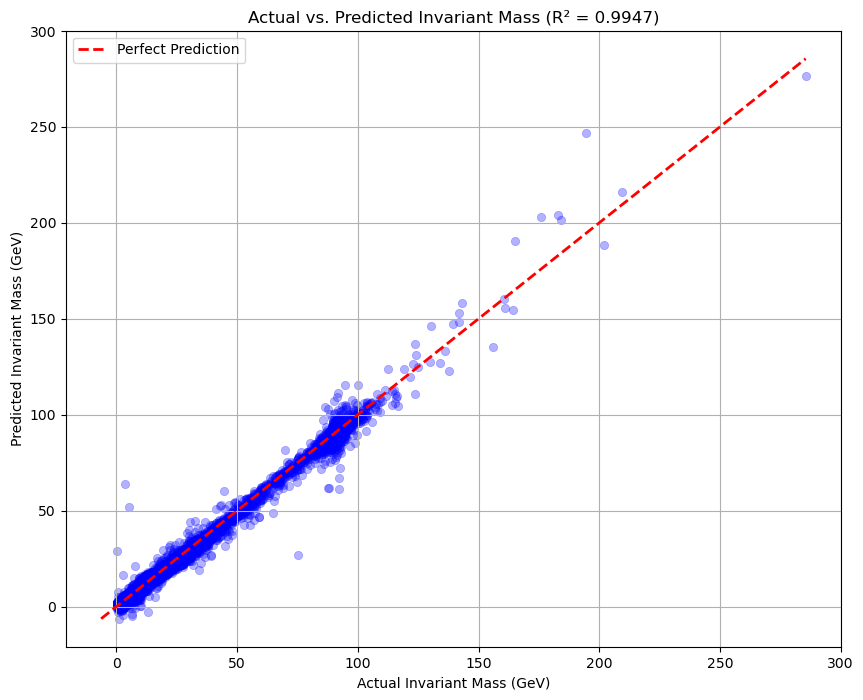

In [49]:
plt.figure(figsize=(10, 8))
sns.scatterplot(x=y_true_original, y=y_pred_original, alpha=0.3, color='blue', edgecolor=None)
min_val = min(y_true_original.min(), y_pred_original.min())
max_val = max(y_true_original.max(), y_pred_original.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Perfect Prediction')
plt.xlabel('Actual Invariant Mass (GeV)')
plt.ylabel('Predicted Invariant Mass (GeV)')
plt.title(f'Actual vs. Predicted Invariant Mass (R² = {r2:.4f})')
plt.legend()
plt.grid(True)
plt.show()

In [50]:
residuals = y_true_original - y_pred_original

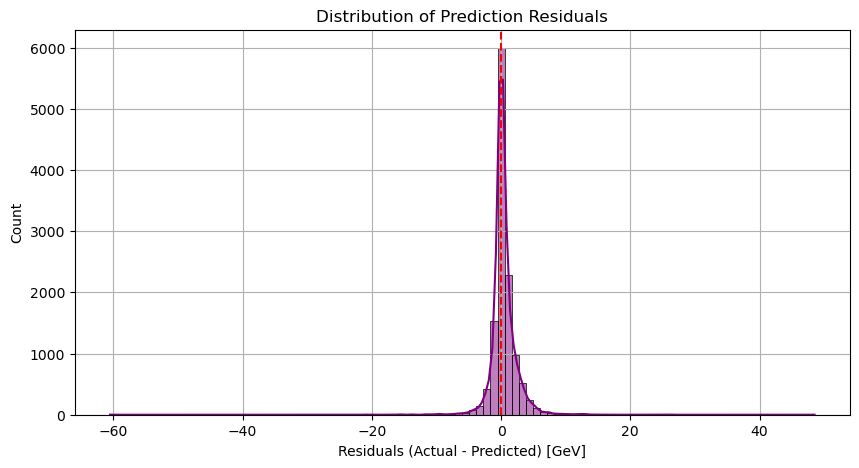

In [51]:
plt.figure(figsize=(10, 5))
sns.histplot(residuals, bins=100, kde=True, color='purple')
plt.axvline(x=0, color='red', linestyle='--', linewidth=1.5)
plt.xlabel('Residuals (Actual - Predicted) [GeV]')
plt.ylabel('Count')
plt.title('Distribution of Prediction Residuals')
plt.grid(True)
plt.show()

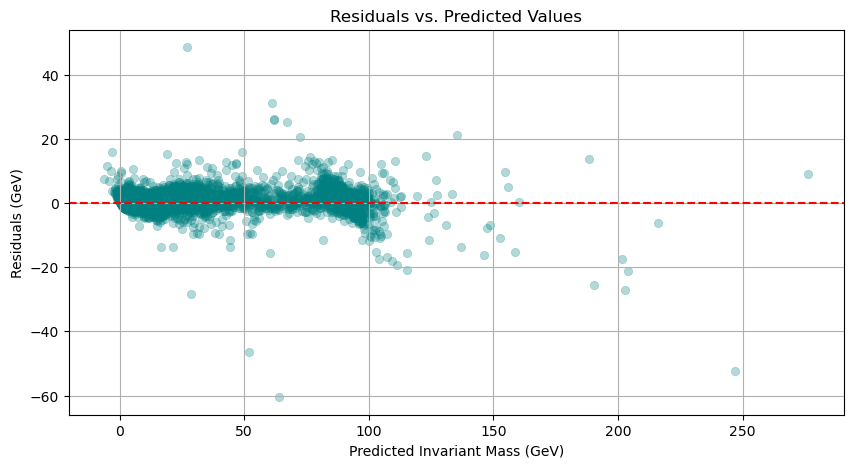

In [52]:
plt.figure(figsize=(10, 5))
sns.scatterplot(x=y_pred_original, y=residuals, alpha=0.3, color='teal', edgecolor=None)
plt.axhline(y=0, color='red', linestyle='--', linewidth=1.5)
plt.xlabel('Predicted Invariant Mass (GeV)')
plt.ylabel('Residuals (GeV)')
plt.title('Residuals vs. Predicted Values')
plt.grid(True)
plt.show()

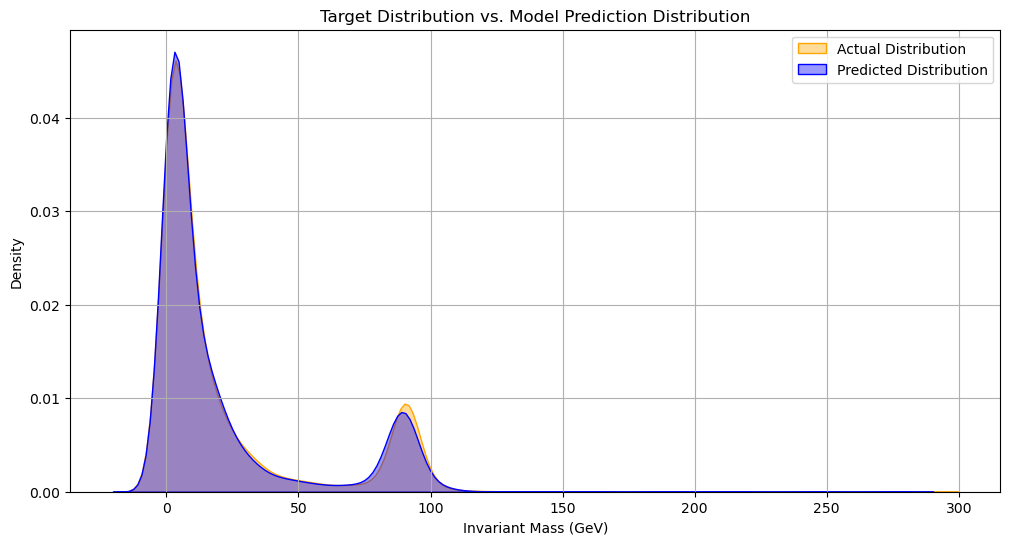

In [53]:
plt.figure(figsize=(12, 6))
sns.kdeplot(y_true_original, label='Actual Distribution', fill=True, alpha=0.4, color='orange')
sns.kdeplot(y_pred_original, label='Predicted Distribution', fill=True, alpha=0.4, color='blue')
plt.xlabel('Invariant Mass (GeV)')
plt.ylabel('Density')
plt.title('Target Distribution vs. Model Prediction Distribution')
plt.legend()
plt.grid(True)
plt.show()

## =====================================================================